In [1]:
import pandas as pd
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report


In [5]:
# Step 1: Load both CSVs
original_df = pd.read_csv(r"shuffled_metadata.csv")
insightface_df = pd.read_csv(r"insightface_predictions.csv")


In [6]:
# Step 2: Normalize the filenames in insightface by removing "_00" suffix
insightface_df["normalized_filename"] = insightface_df["filename"].str.replace(r"_00", "", regex=True)


In [7]:
# Step 3: Filter original_df to keep only images that InsightFace saw
filtered_original_df = original_df[original_df["filename"].isin(insightface_df["normalized_filename"])]


In [8]:
# Step 4: Add age group bin to insightface_df
def get_age_group(age):
    if pd.isna(age):
        return "unknown"
    age = int(age)
    if age < 13:
        return "0-12"
    elif age <= 17:
        return "13-17"
    elif age <= 20:
        return "18-20"
    elif age <= 25:
        return "21-25"
    elif age <= 40:
        return "26-40"
    else:
        return "41+"

insightface_df["age_group"] = insightface_df["age"].apply(get_age_group)

In [9]:
insightface_df.head()


,filename,face_id,age,gender,normalized_filename,age_group
0,img0001.png,0,20,Female,img0001.png,18-20
1,img0002.png,0,26,Female,img0002.png,26-40
2,img0004.png,0,22,Female,img0004.png,21-25
3,img0005.png,0,21,Female,img0005.png,21-25
4,img0006.png,0,25,Female,img0006.png,21-25


In [10]:
# Replace 'filename' with 'normalized_filename'
insightface_df['filename'] = insightface_df['normalized_filename']

# Drop the now redundant column
insightface_df.drop(columns=["normalized_filename"], inplace=True)


In [11]:
insightface_df.drop(columns=["gender", "face_id"], inplace=True, axis=1)


In [13]:
insightface_df.head()

,filename,age,age_group
0,img0001.png,20,18-20
1,img0002.png,26,26-40
2,img0004.png,22,21-25
3,img0005.png,21,21-25
4,img0006.png,25,21-25


In [14]:
# Save results (optional)
filtered_original_df.to_csv("filtered_original_metadata.csv", index=False)
insightface_df.to_csv("insightface_with_age_group.csv", index=False)

print("✅ Processing complete. Files saved.")

✅ Processing complete. Files saved.


In [15]:
# Standardize '41+' and '41plus' to a common label in both DataFrames
insightface_df["age_group"] = insightface_df["age_group"].replace("41+", "41plus")
filtered_original_df.loc[:, "age_group"] = filtered_original_df["age_group"].replace("41+", "41plus")


In [16]:
# Merge for comparison
merged_df = pd.merge(insightface_df, filtered_original_df, on="filename", suffixes=("_pred", "_true"))
merged_df["match"] = merged_df["age_group_pred"] == merged_df["age_group_true"]
accuracy = merged_df["match"].mean()

In [17]:
merged_df.head()


,filename,age,age_group_pred,ethnicity,age_group_true,gender,match
0,img0001.png,20,18-20,Northern European,13-17,male,False
1,img0002.png,26,26-40,East African,13-17,male,False
2,img0004.png,22,21-25,Indian,13-17,male,False
3,img0005.png,21,21-25,Northern European,13-17,male,False
4,img0006.png,25,21-25,South African,18-20,male,False


In [18]:
y_true = merged_df["age_group_true"]
y_pred = merged_df["age_group_pred"]

# Define consistent label order
labels = ["13-17", "18-20", "21-25", "26-40", "41plus"]

# Print classification metrics
print("📊 Classification Report (per age group):\n")
print(classification_report(y_true, y_pred, labels=labels, digits=3))

📊 Classification Report (per age group):

              precision    recall  f1-score   support

       13-17      1.000     0.014     0.027       287
       18-20      0.073     0.014     0.023       217
       21-25      0.143     0.268     0.186       213
       26-40      0.337     0.705     0.456       224
      41plus      0.685     0.780     0.730       173

   micro avg      0.322     0.320     0.321      1114
   macro avg      0.448     0.356     0.285      1114
weighted avg      0.473     0.320     0.252      1114



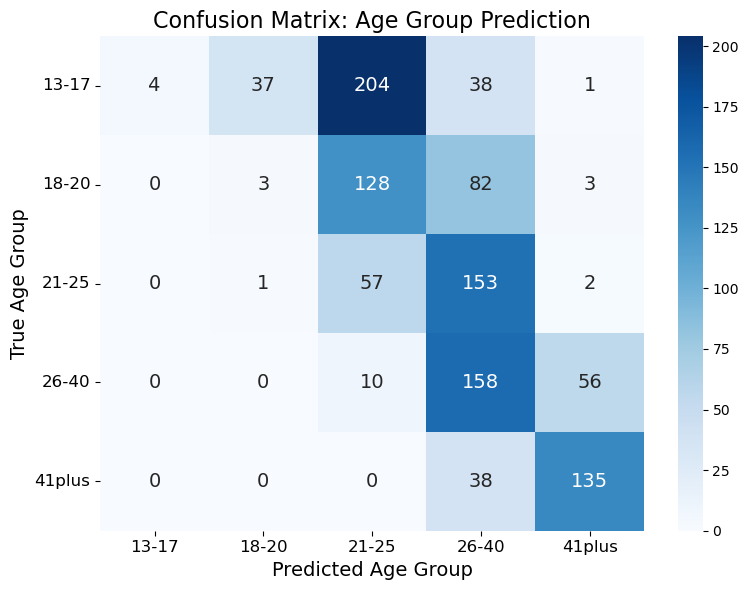

In [20]:
# Confusion Matrix
labels = ["13-17", "18-20", "21-25", "26-40", "41plus"]
cm = confusion_matrix(merged_df["age_group_true"], merged_df["age_group_pred"], labels=labels)
cm_df = pd.DataFrame(cm, index=labels, columns=labels)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm_df,
    annot=True,
    fmt="d",
    cmap="Blues",
    annot_kws={"size": 14}  # increase numbers inside cells
)

plt.title("Confusion Matrix: Age Group Prediction", fontsize=16)
plt.xlabel("Predicted Age Group", fontsize=14)
plt.ylabel("True Age Group", fontsize=14)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12, rotation=0)  # keep y labels horizontal
plt.tight_layout()
plt.show()



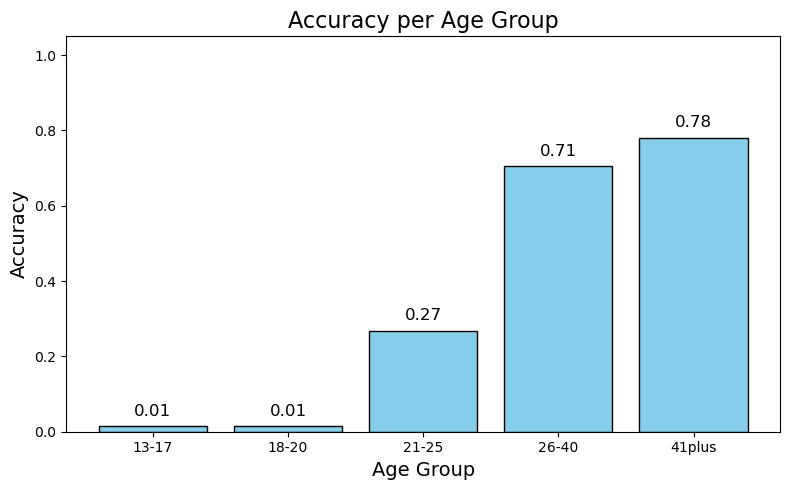

In [21]:

# Labels
labels = ["13-17", "18-20", "21-25", "26-40", "41plus"]

# Compute confusion matrix
cm = confusion_matrix(merged_df["age_group_true"], merged_df["age_group_pred"], labels=labels)

# Accuracy per age group (diagonal / row sum)
accuracies = cm.diagonal() / cm.sum(axis=1)

# Put into DataFrame for clarity
acc_df = pd.DataFrame({
    "Age Group": labels,
    "Accuracy": accuracies
})

# Plot bar chart
plt.figure(figsize=(8, 5))
bars = plt.bar(acc_df["Age Group"], acc_df["Accuracy"], color="skyblue", edgecolor="black")
plt.ylim(0, 1.05)
plt.title("Accuracy per Age Group", fontsize=16)
plt.ylabel("Accuracy", fontsize=14)
plt.xlabel("Age Group", fontsize=14)

# Add value labels on bars
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, height + 0.02, f"{height:.2f}", 
             ha='center', va='bottom', fontsize=12)

plt.tight_layout()
plt.show()
